In [8]:
import time
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.initializers import RandomNormal
from tensorflow.keras.callbacks import LearningRateScheduler





In [9]:
#Generate the neural network architectures
def Archit(K):
    Array = np.arange(1, K[0] + 1)
    Lay_x_Neu = np.column_stack((Array, K[1] * Array))
    return Lay_x_Neu

Lay_x_Neu = Archit([10, 10])

In [10]:
#Experiment parameters

#Training sample sizes: 10 values from 100 to 10,000, on a log scale
Nsamples = np.logspace(2, 4, 10).astype(int)

#Test-set size: 20% of the training-set size
Ntest = (0.2 * Nsamples).astype(int)


In [11]:
#This is the function that we approximate
def funct(samples):
    """Evaluate f2(x, y) = cos(0.2x) cos(0.2y) exp(-pi(x^2 + y^2))."""
    x, y = samples[:, 0], samples[:, 1]
    return (
        np.cos(0.2 * x)
        * np.cos(0.2 * y)
        * np.exp(-np.pi * (x**2 + y**2))
    )


In [12]:
# Generate random sample points uniformly on [-1, 1]^2
rng = np.random.default_rng(42)

def samps(n_samples):
    """Generate independent uniform samples on [-1, 1]^2."""
    return rng.uniform(-1, 1, size=(int(n_samples), 2))


In [13]:
#Create a simple feedforward neural network
def create_simple_NN(X_samp, labels, L, activation='relu'):
    """Create a feedforward neural network for regression."""

    model_input = Input(shape=(X_samp.shape[1],))
    x = model_input

    # Initialize hidden-layer weights and biases from N(0, 0.1^2)
    for i in range(int(L[0])):
        x = Dense(
            int(L[1]),
            activation=activation,
            kernel_initializer=tf.keras.initializers.RandomNormal(
                mean=0.0, stddev=0.1
            ),
            bias_initializer=tf.keras.initializers.RandomNormal(
                mean=0.0, stddev=0.1
            )
        )(x)
        
    # Apply the same initialization to the output layer
    out = Dense(
        1,
        kernel_initializer=tf.keras.initializers.RandomNormal(
            mean=0.0, stddev=0.1
        ),
        bias_initializer=tf.keras.initializers.RandomNormal(
            mean=0.0, stddev=0.1
        )
    )(x)

    model = Model(inputs=model_input, outputs=out)
    return model





In [19]:
#Parameters for training
initial_learning_rate = 0.001
decay_steps = 1000
decay_rate = 0.85
staircase = True

final_epochs = 150
total_runs = 20

VAL_SPLIT = 0
BATCH_SIZE = 50

In [ ]:

# Record the start time for estimating training duration
start_time = time.time()

# Initialize arrays to store results
results = np.zeros((len(Lay_x_Neu), len(Nsamples), total_runs))
history = np.zeros((len(Lay_x_Neu), final_epochs, total_runs))

total_iterations = total_runs * len(Nsamples) * len(Lay_x_Neu)
counter = 0

# Run multiple training experiments
for run in range(total_runs):
    for i in range(len(Nsamples)):

        # Generate training samples and function values
        training_sample = samps(int(Nsamples[i]))
        values = funct(training_sample)

        # Generate independent test samples and function values
        test_sample = samps(int(Ntest[i]))
        test_values = funct(test_sample)

        for j in range(len(Lay_x_Neu)):

            # Exponentially decaying learning-rate schedule
            lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
                initial_learning_rate=initial_learning_rate,
                decay_steps=decay_steps,
                decay_rate=decay_rate,
                staircase=staircase
            )

            # Create a fresh Adam optimizer for this model
            Optimizer = Adam(
                learning_rate=lr_schedule,
                beta_1=0.9,
                beta_2=0.999,
                epsilon=1e-7
            )

            # Create and compile the neural network
            model = create_simple_NN(
                training_sample, values, Lay_x_Neu[j]
            )

            model.compile(
                loss="mean_squared_error",
                optimizer=Optimizer,
                metrics=["mean_squared_error"]
            )

            # Train the model
            hist = model.fit(
                training_sample,
                values,
                validation_split=VAL_SPLIT,
                epochs=final_epochs,
                batch_size=BATCH_SIZE,
                shuffle=True,
                verbose=0
            )

            # Store training MSE history for the largest sample size
            if i == len(Nsamples) - 1:
                history[j, :, run] = hist.history["mean_squared_error"]

            # Evaluate test RMSE
            test_mse = model.evaluate(
                test_sample, test_values, verbose=0
            )[0]

            results[j, i, run] = np.sqrt(test_mse)

            # Display progress and estimated remaining time
            counter += 1
            now_time = time.time()

            remaining_time = (
                (total_iterations - counter)
                * (now_time - start_time)
                / counter
            )

            print(f"Approx. {remaining_time:.1f} seconds remaining")
            print(f"{100 * counter / total_iterations:.2f}% done")


Approx. 7355.1 seconds remaining
0.05% done
Approx. 7390.4 seconds remaining
0.10% done
Approx. 7446.4 seconds remaining
0.15% done
Approx. 8048.7 seconds remaining
0.20% done
Approx. 8259.5 seconds remaining
0.25% done
Approx. 8425.8 seconds remaining
0.30% done
Approx. 8587.2 seconds remaining
0.35% done
Approx. 8785.3 seconds remaining
0.40% done
Approx. 8969.2 seconds remaining
0.45% done
Approx. 9185.3 seconds remaining
0.50% done
Approx. 9128.2 seconds remaining
0.55% done
Approx. 9101.2 seconds remaining
0.60% done
Approx. 9100.1 seconds remaining
0.65% done
Approx. 9114.5 seconds remaining
0.70% done
Approx. 9139.8 seconds remaining
0.75% done
Approx. 9170.3 seconds remaining
0.80% done
Approx. 9371.7 seconds remaining
0.85% done
Approx. 9569.5 seconds remaining
0.90% done
Approx. 9760.5 seconds remaining
0.95% done
Approx. 9994.5 seconds remaining
1.00% done
Approx. 9934.1 seconds remaining
1.05% done
Approx. 9895.6 seconds remaining
1.10% done
Approx. 9872.4 seconds remaining

In [14]:
results = np.load("resultsNN2D.npy")
print(results.shape)

(10, 10, 20)


In [15]:
plt.figure(figsize=(12, 8))

<Figure size 1200x800 with 0 Axes>

<Figure size 1200x800 with 0 Axes>

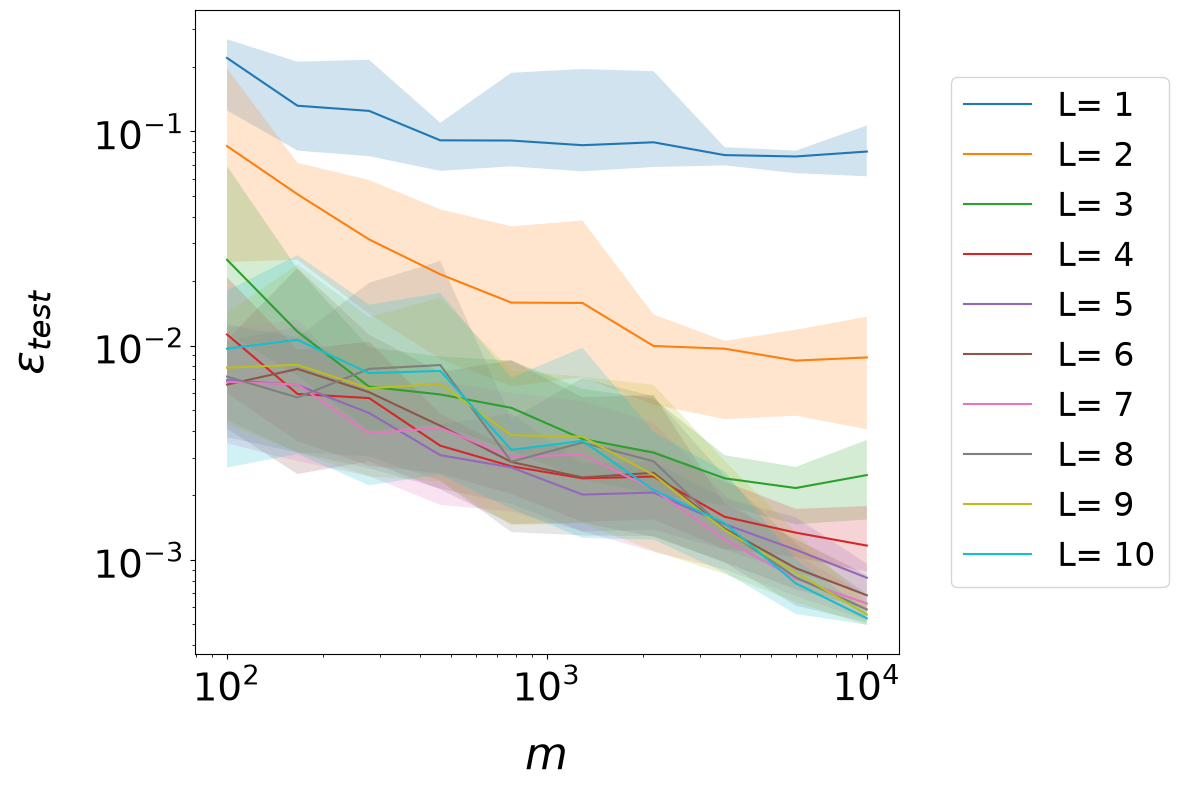

In [16]:
#Plot Error over training set sizes
plt.figure(figsize=(12, 8))  #Size
results_mean = np.mean(results, axis = 2)
results_lower = np.sort(results, axis = 2)[:,:,1] # 90% confidence intervals
results_upper = np.sort(results, axis = 2)[:,:,-2] # 90% confidence intervals

for i in range(len(Lay_x_Neu)):
    plt.loglog(Nsamples, results_mean[i,:], label=f'L= {i + 1}')
    plt.fill_between(Nsamples, results_lower[i,:], results_upper[i,:],  alpha=0.2)

plt.xlabel(r'$m$', fontsize=32, labelpad=18)
plt.ylabel(r'$\epsilon_{test}$', fontsize=32, labelpad=28)


# Increase font size of axis tick labels
plt.tick_params(axis='both', which='major', labelsize=28)  # Major ticks
plt.tick_params(axis='both', which='minor', labelsize=28)  # Minor ticks

plt.legend(fontsize=28, loc='lower left')

plt.legend(
    fontsize=24,
    loc='center left',
    bbox_to_anchor=(1.05, 0.5),  # Place the legend to the right of the plot
    ncol=1  # Single column for legend entries
)

plt.tight_layout()  # Adjust the picture

plt.savefig("errorNN2D.pdf")


plt.show()